In [ ]:
import pandas as pd
import seaborn as sns

import matplotlib
import matplotlib.pyplot as plt 
plt.style.use('ggplot')
from matplotlib.pyplot import figure 

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)
df = pd.read_csv(r'C:\Users\kelvi\downloads\movies.csv')


In [ ]:
#read the data
df.head()

In [ ]:
df.dtypes #data types in df

In [ ]:
#change the data types in columns
df['budget'] = df['budget'].astype('Int64')
df['gross'] = df['gross'].astype('Int64')
#check by looking back into the df
#df

In [ ]:
#Creating a new column for the Current year
df['CurrentYear'] = df['released'].astype(str).str[8:-15]

In [ ]:
df.head()

In [ ]:
df.sort_values(by=['gross'], inplace=False, ascending=False)

In [ ]:
pd.set_option('display.max_rows',None)

In [38]:
#Find any duplicates then dropping them
df['company'] = df['company'].drop_duplicates().sort_values(ascending=False)

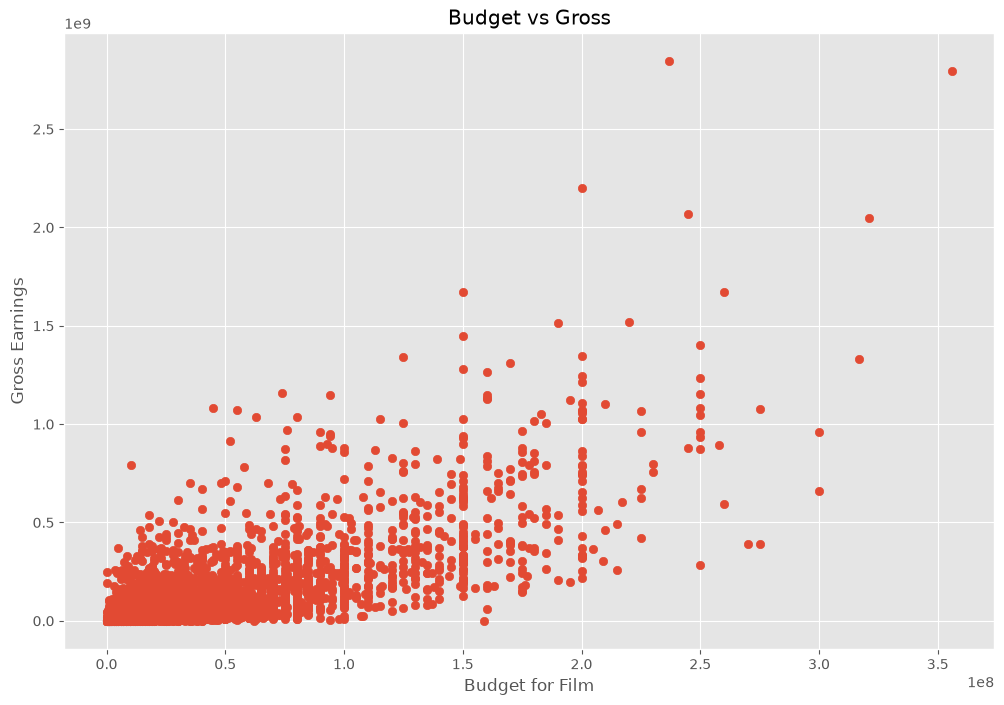

In [40]:
#Scatter plot with budget vs gross

plt.scatter(x=df['budget'],y=df['gross'])
plt.title('Budget vs Gross')
plt.xlabel('Budget for Film')
plt.ylabel('Gross Earnings')

plt.show()

<Axes: xlabel='budget', ylabel='gross'>

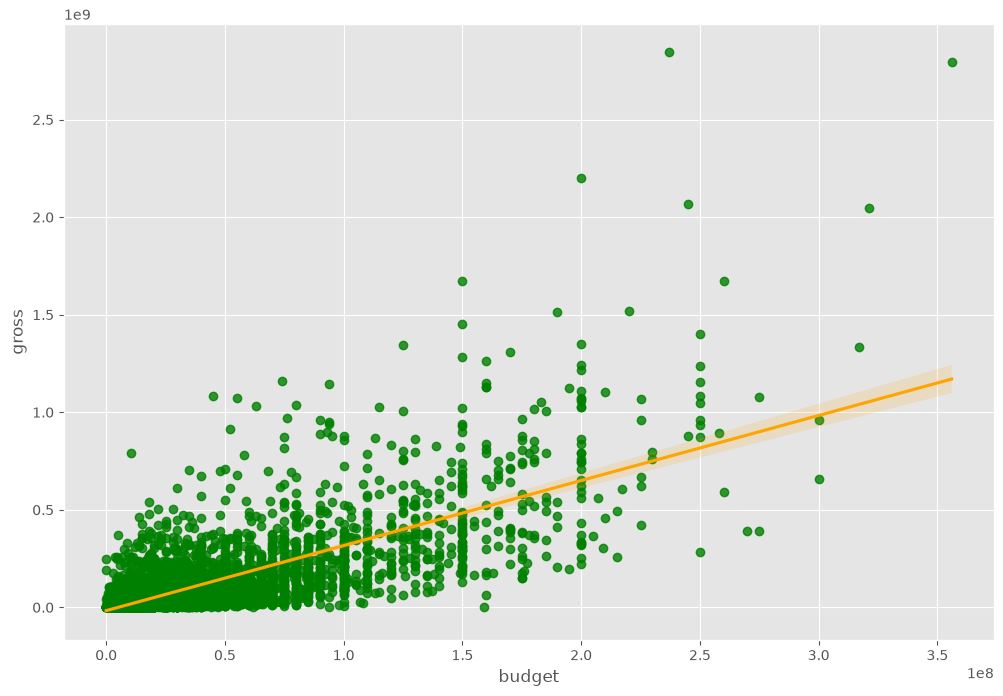

In [44]:
#Correlation line between Budget and Gross

sns.regplot(x='budget',y='gross', data =df, scatter_kws={"color":"Green"},line_kws={"color":"orange"})
#A higher budget has a positive correlation with the gross earnings of a film

In [46]:
df.corr(method='pearson',numeric_only='True')
#it appears that budget and gross has the highets correlation of 0.7
#Will use different methods like kendall and spearman to ensure the accuracy of this finding.

,year,score,votes,budget,gross,runtime
year,1.000000,0.097995,0.222945,0.329321,0.257486,0.120811
score,0.097995,1.000000,0.409182,0.076254,0.186258,0.399451
votes,0.222945,0.409182,1.000000,0.442429,0.630757,0.309212
budget,0.329321,0.076254,0.442429,1.000000,0.740395,0.320447
gross,0.257486,0.186258,0.630757,0.740395,1.000000,0.245216
runtime,0.120811,0.399451,0.309212,0.320447,0.245216,1.000000


In [47]:
df.corr(method='kendall',numeric_only='True')

,year,score,votes,budget,gross,runtime
year,1.000000,0.067652,0.331465,0.224120,0.200618,0.097184
score,0.067652,1.000000,0.300115,-0.000566,0.086046,0.283611
votes,0.331465,0.300115,1.000000,0.353702,0.548899,0.198240
budget,0.224120,-0.000566,0.353702,1.000000,0.512637,0.235483
gross,0.200618,0.086046,0.548899,0.512637,1.000000,0.168933
runtime,0.097184,0.283611,0.198240,0.235483,0.168933,1.000000


In [48]:
df.corr(method='spearman',numeric_only='True')
#It appears that budget and gross has a consistent finding to be above 0.5

,year,score,votes,budget,gross,runtime
year,1.000000,0.099045,0.469829,0.317336,0.293084,0.142977
score,0.099045,1.000000,0.428138,-0.001403,0.126116,0.399857
votes,0.469829,0.428138,1.000000,0.502466,0.742050,0.290159
budget,0.317336,-0.001403,0.502466,1.000000,0.693670,0.336370
gross,0.293084,0.126116,0.742050,0.693670,1.000000,0.246243
runtime,0.142977,0.399857,0.290159,0.336370,0.246243,1.000000


<function matplotlib.pyplot.show(close=None, block=None)>

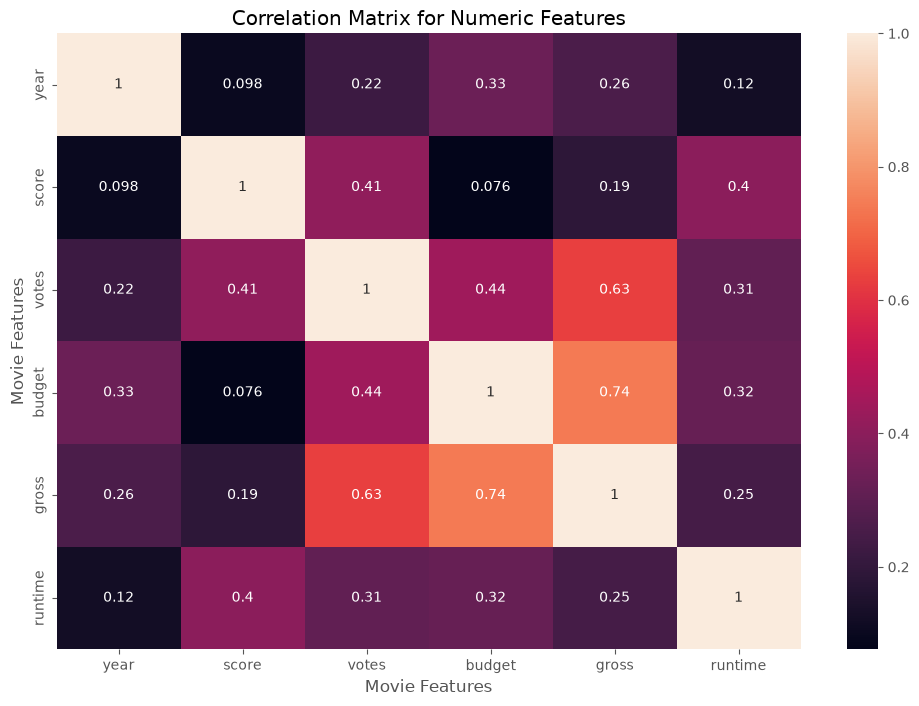

In [50]:
#heat map 
#can use different methods as before to ensure the accuracy of the findings.
correlation_matrix = df.corr(method='pearson',numeric_only='true')
sns.heatmap(correlation_matrix,annot=True)
plt.title('Correlation Matrix for Numeric Features')
plt.xlabel('Movie Features')
plt.ylabel('Movie Features')
plt.show

In [69]:
#Convert non numeric columns into numeric to compare all the columns to see the highest correlations.
df_numerized = df.copy()

for col_name in df_numerized.columns:
    if df_numerized[col_name].dtype == 'object' or df_numerized[col_name].dtype == 'str': 
        df_numerized[col_name] = df_numerized[col_name].astype('category').cat.codes
        df_numerized

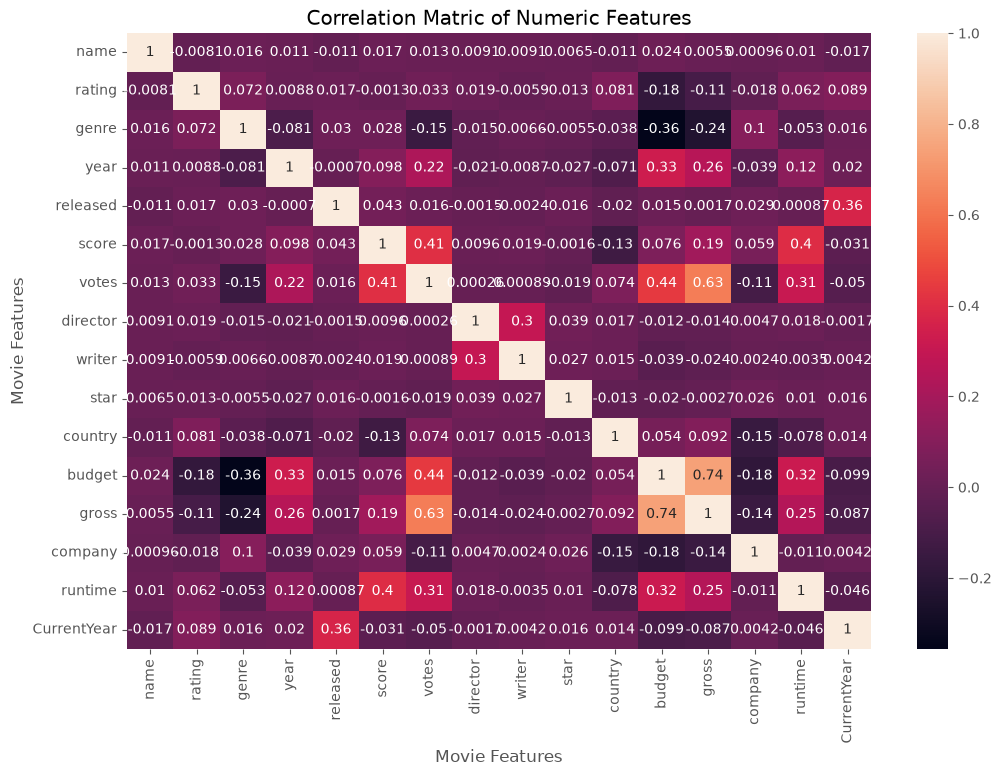

In [71]:
#look in the correlation of all the columns in this df

correlation_matrix = df_numerized.corr(method='pearson')
sns.heatmap(correlation_matrix,annot=True)
plt.title('Correlation Matric of Numeric Features')
plt.xlabel('Movie Features')
plt.ylabel('Movie Features')
plt.show()

In [ ]:
#correlation of all the columns and seeinf the highest correlations
df_numerized.corr() 

In [82]:
#Using unstack to quickly find the strongest relationships between variable.
correlation_mat = df_numerized.corr(numeric_only='true')
corr_pairs = correlation_mat.unstack()
corr_pairs

name         name           1.000000
             rating        -0.008069
             genre          0.016355
             year           0.011453
             released      -0.011311
                              ...   
CurrentYear  budget        -0.099299
             gross         -0.087446
             company        0.004214
             runtime       -0.045921
             CurrentYear    1.000000
Length: 256, dtype: float64

In [83]:
#Finding the strongest relationship with all the variables.
correlation_mat = df_numerized.corr(numeric_only=True)

correlation_pairs = correlation_mat.unstack()
correlation_pairs = correlation_pairs[correlation_pairs != 1]
correlation_pairs = correlation_pairs.drop_duplicates()
correlation_pairs = correlation_pairs.sort_values(
    key=abs, ascending=False
)

print(correlation_pairs)

budget    gross       0.740395
votes     gross       0.630757
          budget      0.442429
score     votes       0.409182
          runtime     0.399451
                        ...   
name      company     0.000961
votes     writer      0.000892
released  runtime     0.000868
year      released   -0.000695
votes     director    0.000260
Length: 120, dtype: float64


In [79]:
high_corr = sorted_pairs[(sorted_pairs) > 0.5]
high_corr

votes        gross          0.630757
gross        votes          0.630757
budget       gross          0.740395
gross        budget         0.740395
director     director       1.000000
votes        votes          1.000000
released     released       1.000000
score        score          1.000000
rating       rating         1.000000
name         name           1.000000
genre        genre          1.000000
year         year           1.000000
budget       budget         1.000000
country      country        1.000000
writer       writer         1.000000
star         star           1.000000
company      company        1.000000
gross        gross          1.000000
runtime      runtime        1.000000
CurrentYear  CurrentYear    1.000000
dtype: float64